# Supplementary Decision Tree — IT25100429
EBM remains my assigned model. This additional classifier offers visual root-to-leaf explanations and a comparison of complexity and class weighting. It uses the shared development folds, with holdout data excluded. The six-model group registry remains unchanged.

Six varieties: D01 depth 3 unweighted, D02 depth 3 balanced, D03 depth 6 unweighted, D04 depth 6 balanced, D05 depth 12 balanced and D06 unlimited balanced. All use minimum leaf size 50. The bounded grid uses inner Average Precision to select each outer-fold winner. See the report for fit counts, metrics, limitations and improvements.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"configs/feature_contract.yaml").exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.models.decision_tree_experiment import run
pd.set_option("display.max_columns",None)
RUN_TRAINING=False
if RUN_TRAINING:run(ROOT)
out=ROOT/"results/models/decision_tree/individual_IT25100429"
display(pd.DataFrame([json.loads((out/"summary_metrics.json").read_text())]))
display(pd.read_csv(out/"variety_comparison.csv"))
display(pd.read_csv(out/"standardization_sensitivity.csv"))

,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,mean_fold_ap,sd_fold_ap,development_rows,formal_holdout_accessed,primary_protocol,inner_fits,outer_variety_refits,standardization_sensitivity_fits,final_model_frozen
0,0.098198,0.494415,0.097829,0.432193,0.159545,0.494426,0.5442,0.217863,40075,31917,4547,3461,35378,0.442225,0.098708,0.001166,80000,False,six-candidate inner AP selection; full outer-t...,30,30,5,False


,candidate_id,mean_fold_ap,sd_fold_ap,mean_train_ap,mean_roc_auc,mean_brier,mean_recall,mean_f1
0,D01,0.100155,0.001217,0.103962,0.499633,0.090146,0.000000,0.000000
1,D02,0.100307,0.001434,0.103833,0.500649,0.249942,0.810560,0.178089
2,D03,0.098562,0.001670,0.117077,0.492608,0.090574,0.000000,0.000000
3,D04,0.099004,0.001165,0.115405,0.496542,0.250209,0.531958,0.166900
4,D05,0.099739,0.002540,0.168829,0.498869,0.249610,0.429315,0.162349
5,D06,0.100286,0.002161,0.233860,0.498267,0.248201,0.408088,0.158305


,fold,raw_ap,standardized_ap,max_absolute_probability_difference,identical_predictions
0,1,0.101915,0.101915,0.0,True
1,2,0.098561,0.098561,0.0,True
2,3,0.101514,0.101514,0.0,True
3,4,0.099243,0.099243,0.0,True
4,5,0.100303,0.100303,0.0,True


## Visual demonstration
The shallow D02 tree was fitted on fold 1 training rows. Follow a condition at each node to a leaf. Leaf class proportions reflect class weighting and are not automatically calibrated resignation probabilities. This illustration is not a final deployment model.

Compare training and outer-validation AP to explain overfitting. Read the confusion matrix at the unchanged 0.50 threshold. Feature importance describes the fitted tree, not causes.

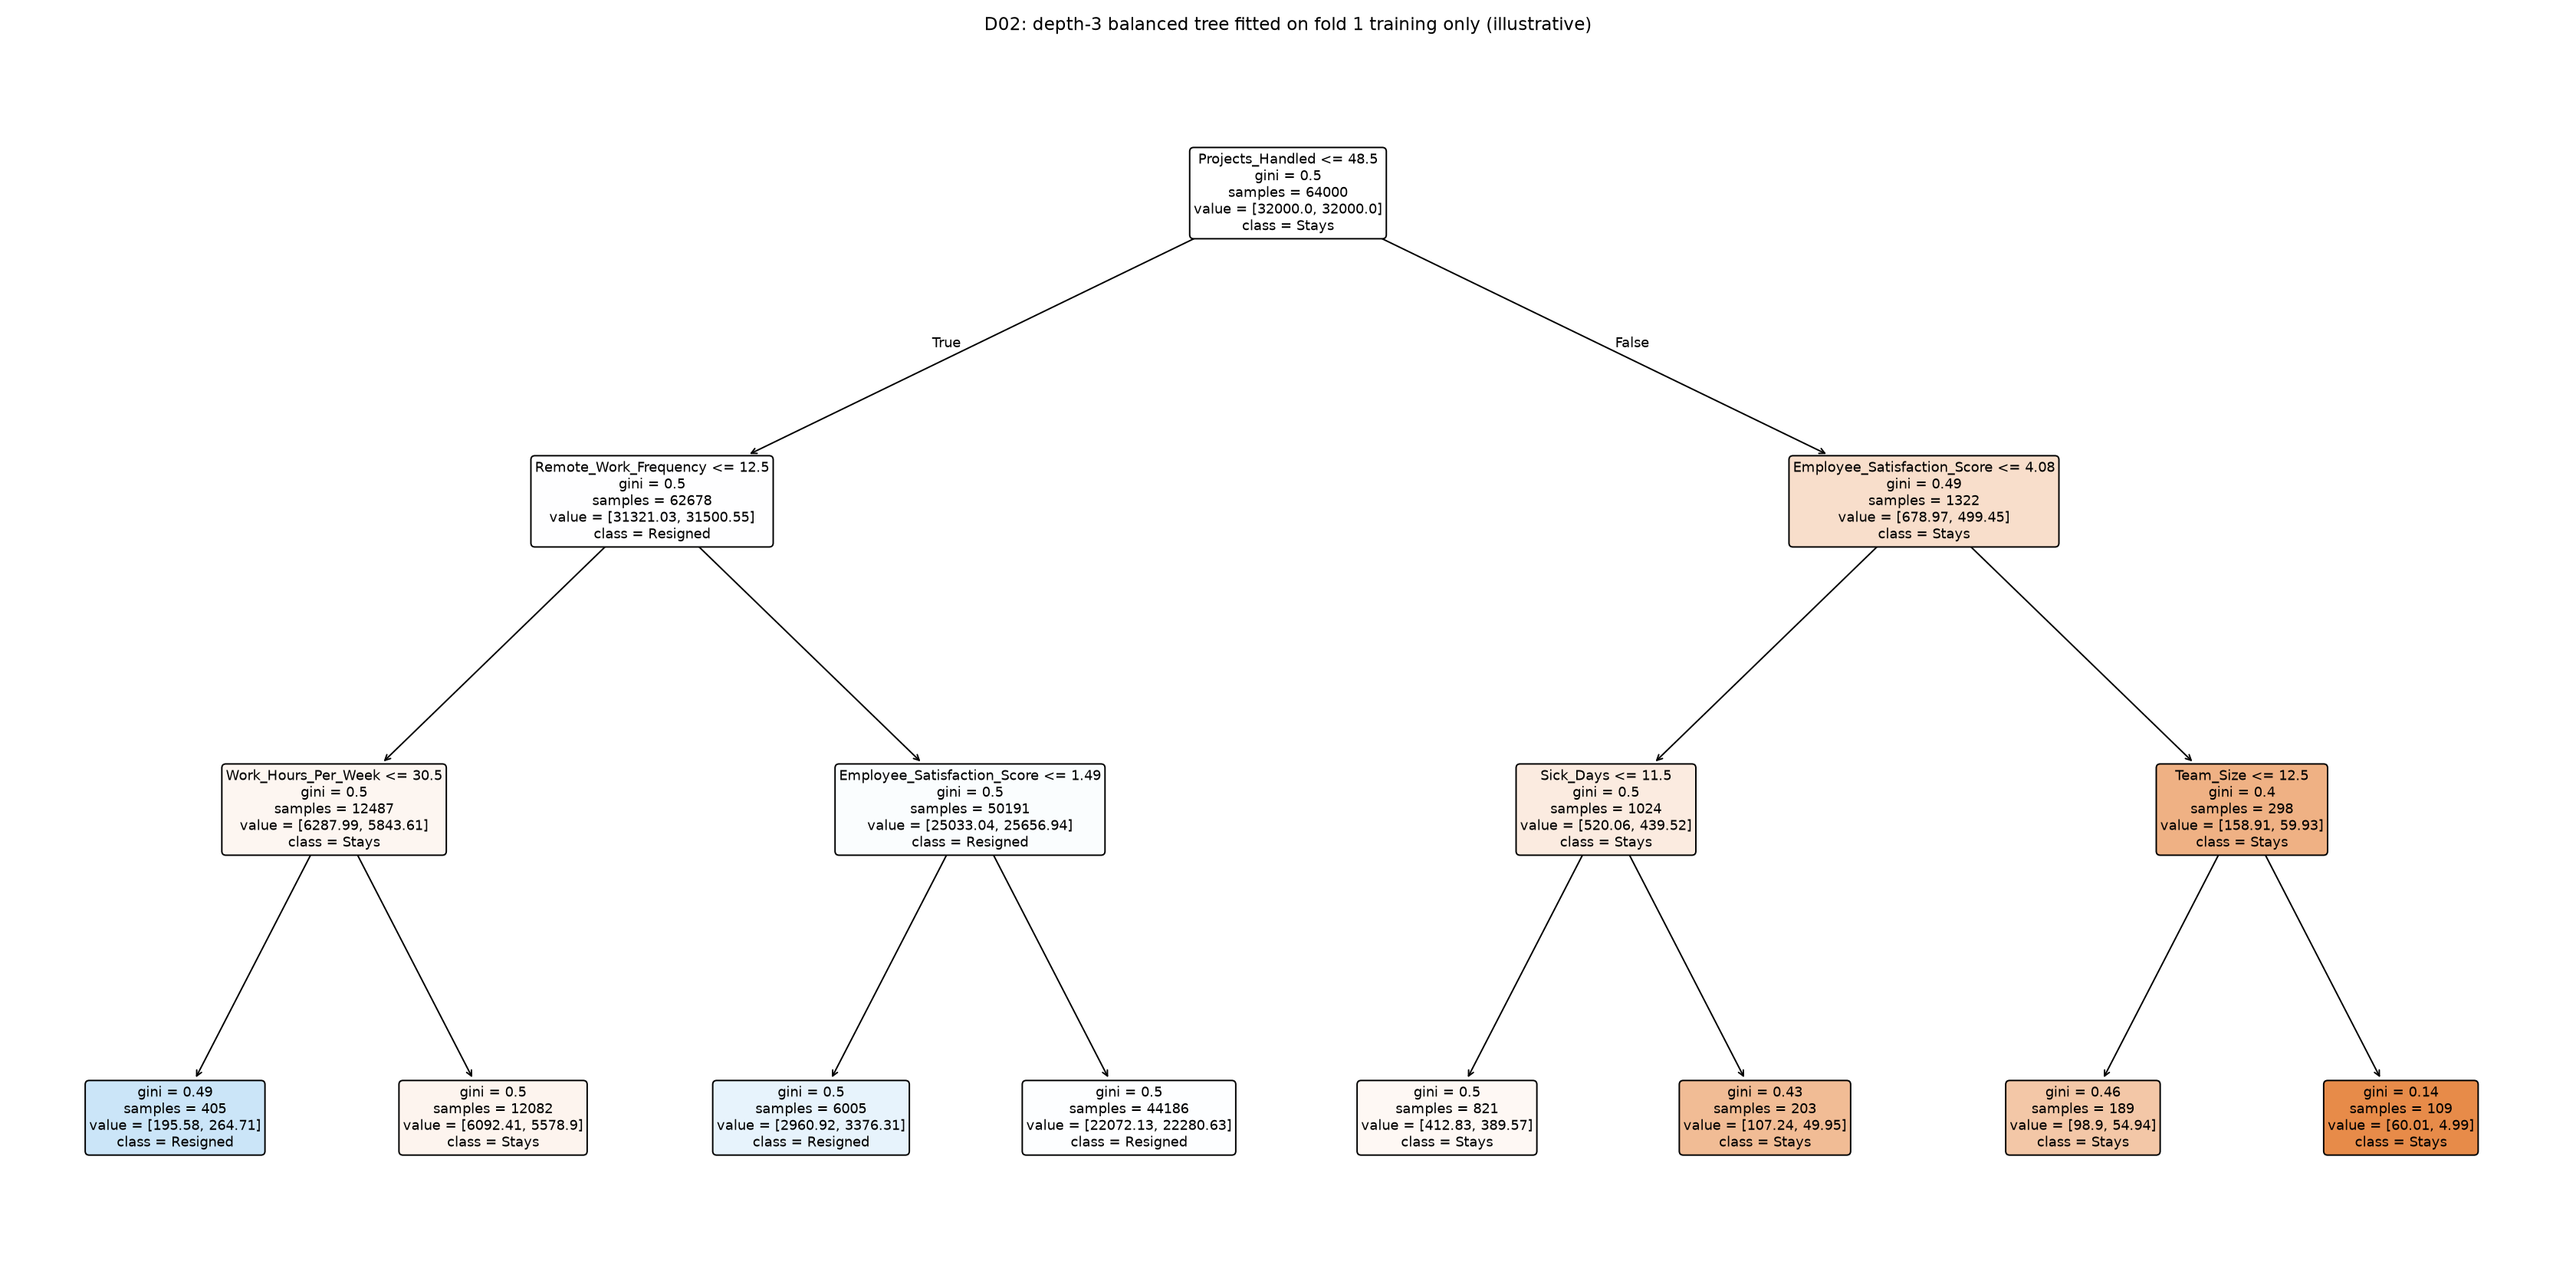

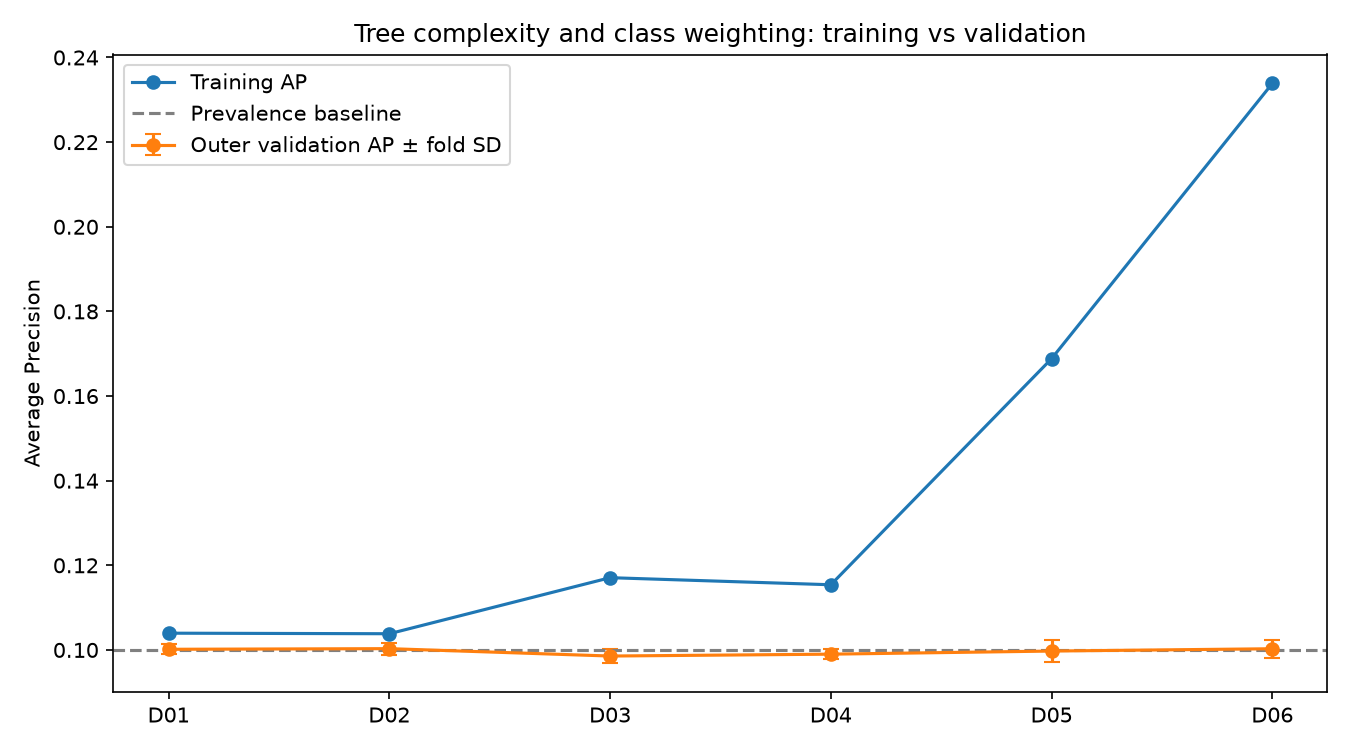

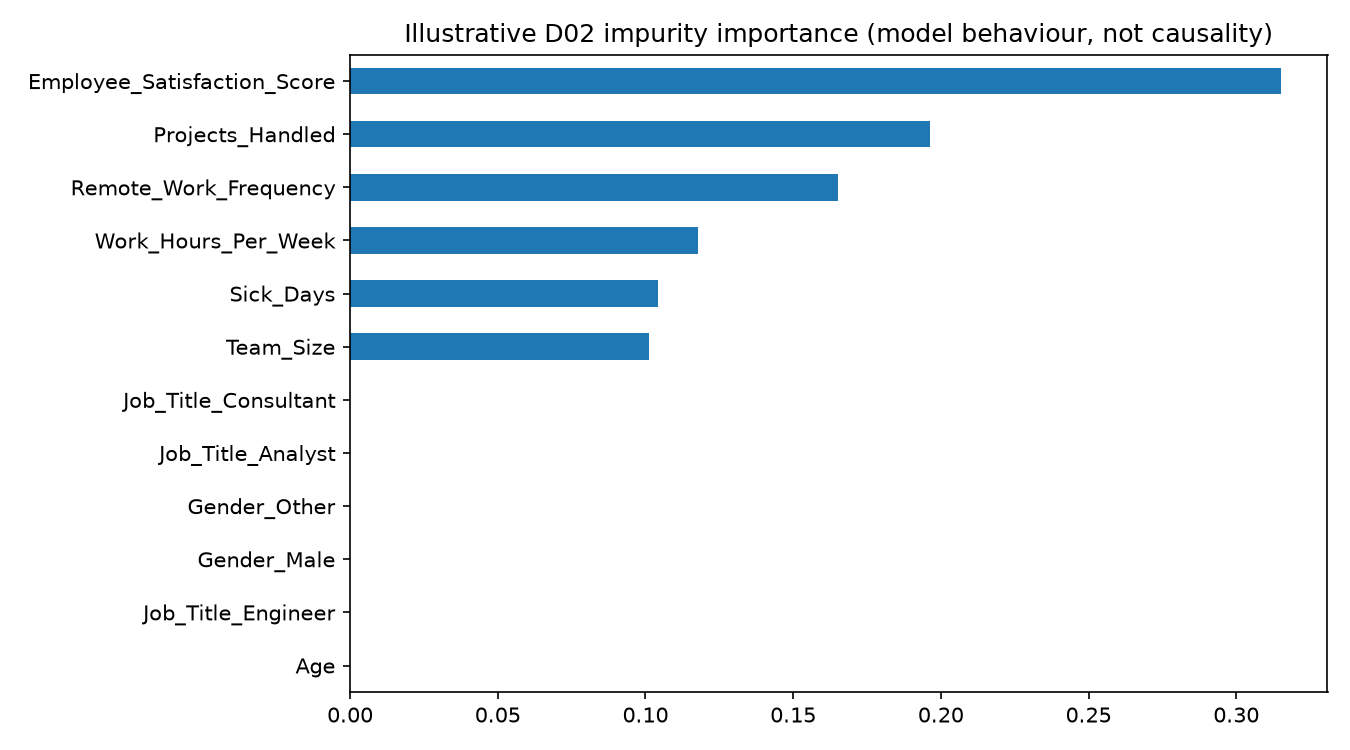

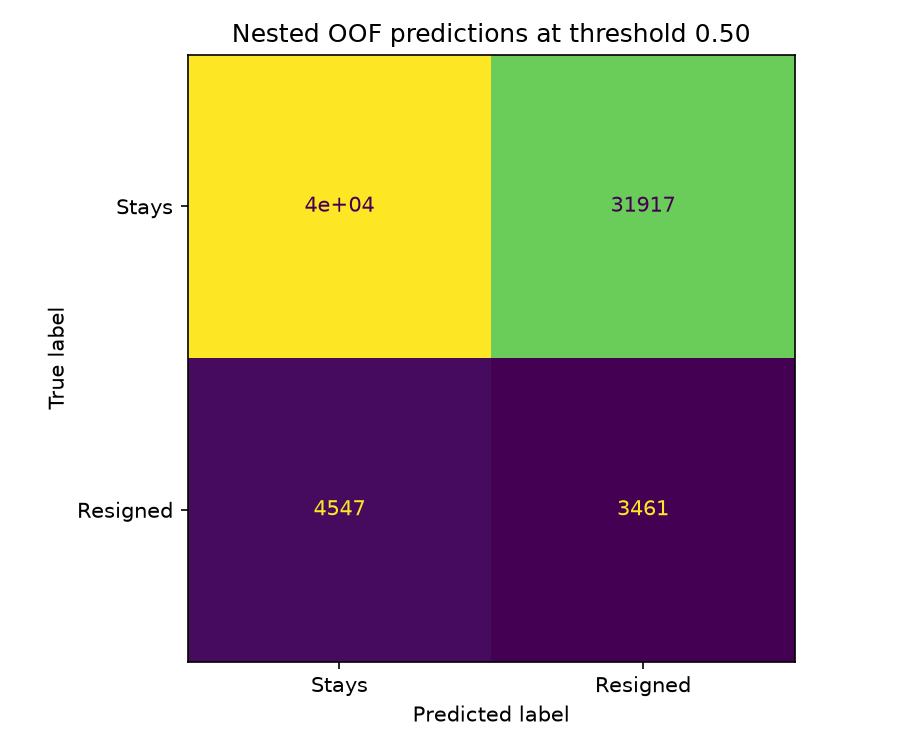

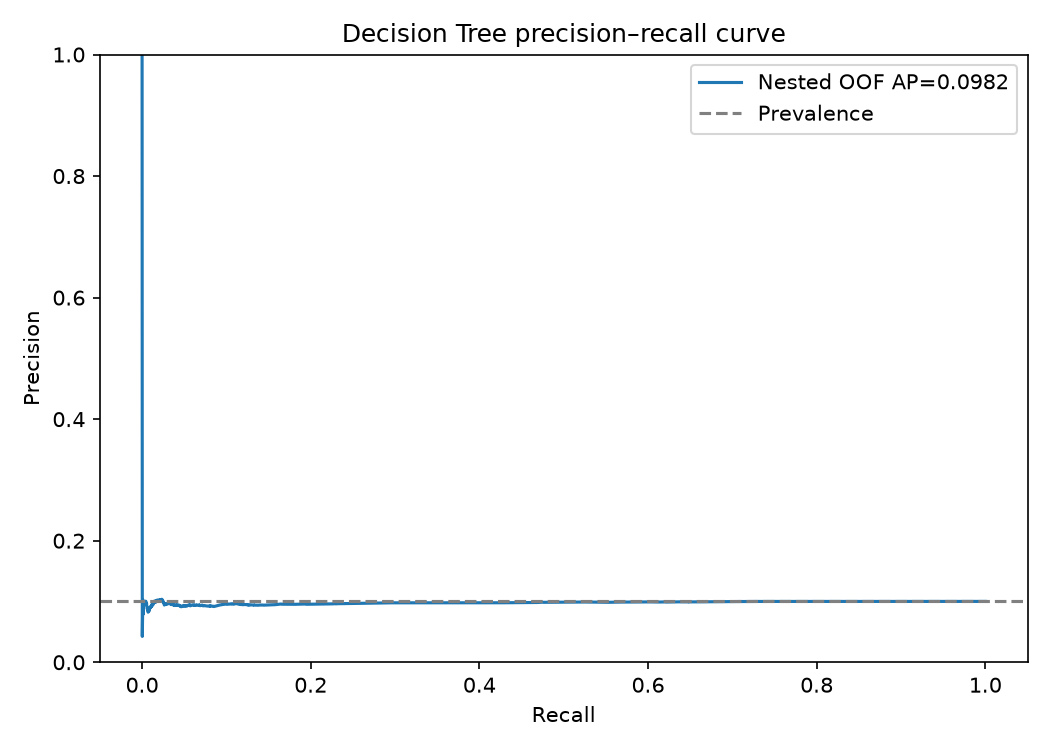

# IT25100429 — supplementary Decision Tree experiment

EBM remains the assigned individual model; this Decision Tree is supplementary and does not replace one of the group's six registered inputs.

## Implementation and validation
Scikit-learn DecisionTreeClassifier, ColumnTransformer, OneHotEncoder and Pipeline. Categorical encoding is fitted inside training. Six candidates pair depth 3/6 with none/balanced weighting, plus depth 12/unlimited balanced trees. Every tree uses min_samples_leaf=50 and random_state=42. A bounded manual grid evaluates all six on a stratified 15% inner validation split inside each frozen outer training fold. Inner AP selects the winner, which is freshly fitted on the full 64,000 outer-training rows. Fixed-candidate outer scores are descriptive variety comparisons, not the selection rule. All 80,000 development employees receive exactly one selected-model OOF prediction. The 20,000-row holdout is excluded before reading its labels or predictors.

30 inner fits + 30 fixed-candidate outer refits (including selected winners) + 5 standardized D02 sensitivity fits = 65 total fits. The demonstration tree reuses fold 1 D02, without an additional all-data fit.

## Results
Nested mean fold AP: 0.098708 ± 0.001166; pooled AP: 0.098198; pooled ROC-AUC: 0.494415; Brier: 0.217863; recall at .50: 0.432193; F1 at .50: 0.159545. Prevalence/no-skill AP is 0.10010. Fold SD is descriptive, not a confidence interval.

```text
candidate_id  mean_fold_ap  sd_fold_ap  mean_train_ap  mean_roc_auc  mean_brier  mean_recall  mean_f1
         D01      0.100155    0.001217       0.103962      0.499633    0.090146     0.000000 0.000000
         D02      0.100307    0.001434       0.103833      0.500649    0.249942     0.810560 0.178089
         D03      0.098562    0.001670       0.117077      0.492608    0.090574     0.000000 0.000000
         D04      0.099004    0.001165       0.115405      0.496542    0.250209     0.531958 0.166900
         D05      0.099739    0.002540       0.168829      0.498869    0.249610     0.429315 0.162349
         D06      0.100286    0.002161       0.233860      0.498267    0.248201     0.408088 0.158305
```

## Interpretation and limitations
AP is appropriate for the 10.01% minority class; ROC-AUC describes ranking, Brier probability error, and recall/F1 describe detection at the fixed .50 threshold. Accuracy alone is misleading. Interpret scores against chance AP .1001 and ROC .5; small numerical differences do not establish practical usefulness. Greater training performance without validation improvement illustrates overfitting. Balanced class weights can shift probability scales and calibration. No threshold was tuned on outer folds.

Tree splits are interpretable but can be unstable. Impurity importance is model-specific, can favour high-cardinality features, and is not causal. The visualization is one shallow fold-local illustration, not a frozen final selected model. Repeated seeds/inner validation, pruning, better predictors and probability calibration are possible future improvements. Raw vs standardized D02 scores are in standardization_sensitivity.csv; scaling generally preserves tree split ordering, with possible floating-point differences.

## Demonstration
Open the notebook, Run All in saved-review mode, display the shallow tree, follow a root-to-leaf path, compare train/validation AP, then explain the confusion matrix and PR curve. Saved files reside in results/models/decision_tree/individual_IT25100429/. No final holdout evaluation or deployment model is claimed.

## Observed conclusion
The selected procedure achieved mean fold AP 0.098708 and pooled AP 0.098198, below the .1001 prevalence reference. D02 was the numerical fixed-variety mean-AP leader (0.100307), a negligible difference from chance; it is not an independently selected final model. The deeper unlimited tree raised mean training AP to 0.233860 while outer AP stayed near 0.100286: a clear overfitting demonstration. D02 raw and standardized predictions were exactly identical in all five folds. Nested recall .432193 was accompanied by 31,917 false positives and precision .097829, so increased detection did not establish useful prediction.


In [2]:
for name in ["tree_diagram.png","overfitting_comparison.png","feature_importance.png","confusion_matrix.png","precision_recall_curve.png"]:
    display(Image(filename=str(out/name)))
display(Markdown((ROOT/"reports/IT25100429_Decision_Tree_Experiment.md").read_text()))